Flight Price Prediction
Predicting Indian domestic flight prices from airline, route, timing, stops, class and days left before departure.

In [2]:
!pip install kagglehub

In [4]:
import os
import kagglehub
import pandas as pd
import numpy as np

In [6]:
path = kagglehub.dataset_download("shubhambathwal/flight-price-prediction")
print("Downloaded to:", path)
print("Files:", os.listdir(path))

Downloaded to: C:\Users\Welcome\.cache\kagglehub\datasets\shubhambathwal\flight-price-prediction\versions\2
Files: ['business.csv', 'Clean_Dataset.csv', 'economy.csv']


In [8]:
df = pd.read_csv(os.path.join(path, "Clean_Dataset.csv"))
print("Shape:", df.shape)
df.head()

Shape: (300153, 12)


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [12]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [14]:
dupes = df.drop(columns=["Unnamed: 0"]).duplicated().sum()
print("Duplicate rows:", dupes)

Duplicate rows: 0


In [16]:
df.groupby("class")["price"].describe()

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Business,93487.0,52540.081124,12969.314606,12000.0,45185.0,53164.0,60396.0,123071.0
Economy,206666.0,6572.342383,3743.519517,1105.0,4173.0,5772.0,7746.0,42349.0


**Finding 1:** Business fares are about 9× Economy fares (median ₹53,164 vs ₹5,772).
The overall mean (₹20,890) sits far above the overall median (₹7,425) because the two classes are mixed together.
Within each class, mean and median are close. Business is about 31% of tickets, so it's a real group, not outliers.

In [18]:
## Dropping columns that won't help

print("Unique flight codes:", df["flight"].nunique())
print("Unique airlines:    ", df["airline"].nunique())
print(df["airline"].unique())

Unique flight codes: 1561
Unique airlines:     6
['SpiceJet' 'AirAsia' 'Vistara' 'GO_FIRST' 'Indigo' 'Air_India']


In [20]:
df = df.drop(columns=["Unnamed: 0", "flight"])
print("Shape after drop:", df.shape)
df.head()

Shape after drop: (300153, 10)


,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


**Finding 2:** `flight` has 1,561 unique codes but only 6 airlines. The code works like an ID
(the model would memorise it rather than learn a pattern), and its useful part, the airline, is already in `airline`.
So `flight` was dropped. `Unnamed: 0` is just a row counter, so it was dropped too.

In [22]:
import matplotlib.pyplot as plt

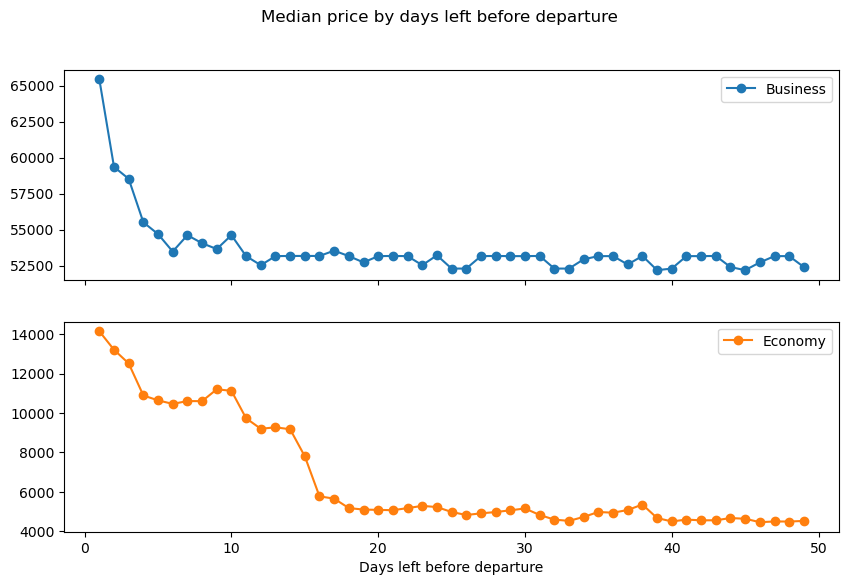

In [26]:
## What drives price?

median_by_day = df.groupby(["days_left", "class"])["price"].median().unstack()

median_by_day.plot(subplots=True, figsize=(10, 6), marker="o",
                   title="Median price by days left before departure")
plt.xlabel("Days left before departure")
plt.show()

**Finding 3:** Price rises sharply when booking close to departure. Economy fares stay fairly flat beyond about two weeks out,
then climb in steps to around 3× by day 1. Business shows the same pattern, but milder and only in the last week or so.
The relationship is not a straight line, which a linear model will struggle to capture.

class      Business  Economy
airline                     
AirAsia         NaN   3276.0
Air_India   49613.0   6082.0
GO_FIRST        NaN   5336.0
Indigo          NaN   4453.0
SpiceJet        NaN   5654.0
Vistara     56588.0   6461.0


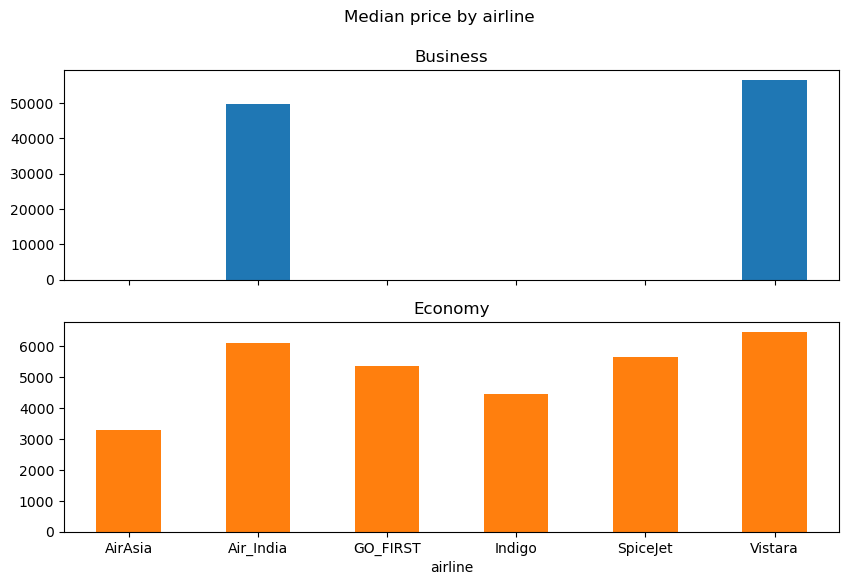

In [29]:
median_by_airline = df.groupby(["airline", "class"])["price"].median().unstack()
print(median_by_airline)

median_by_airline.plot(kind="bar", subplots=True, figsize=(10, 6), legend=False,
                       title="Median price by airline")
plt.xticks(rotation=0)
plt.show()

**Finding 4:** Only Air India and Vistara sell Business class; the other four airlines are Economy-only.
Comparing Economy fares alone, AirAsia is cheapest (median ~₹3,300) and Vistara the most expensive (~₹6,450), about a 2× spread.
Without splitting by class, Vistara and Air India would look far pricier simply because they sell Business tickets.

class        Business  Economy
stops                         
zero          27864.0   3531.0
one           54608.0   5937.0
two_or_more   68743.0   8012.0

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64


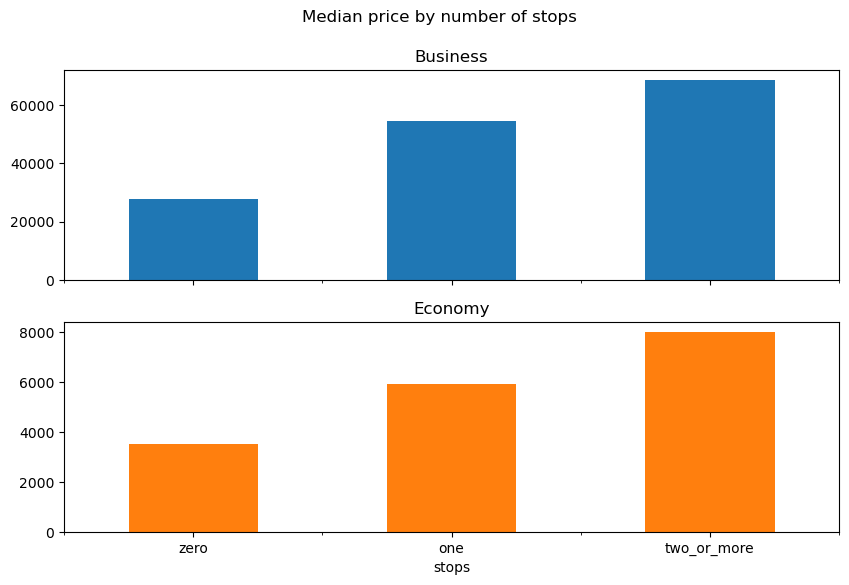

In [31]:
stop_order = ["zero", "one", "two_or_more"]

median_by_stops = df.groupby(["stops", "class"])["price"].median().unstack().reindex(stop_order)
print(median_by_stops)
print()
print(df["stops"].value_counts())

median_by_stops.plot(kind="bar", subplots=True, figsize=(10, 6), legend=False,
                     title="Median price by number of stops")
plt.xticks(rotation=0)
plt.show()

**Finding 5:** Contrary to my expectation, more stops means a higher price in both classes
(Economy median ₹3,531 non-stop → ₹5,937 one stop → ₹8,012 two or more; Business ₹27,864 → ₹54,608 → ₹68,743).
Most tickets (~84%) are one-stop; non-stop is ~12% and two-or-more ~4% (13,286 tickets, enough for a reliable median).
Likely reasons: a stopover ticket is two flight legs, and multi-stop journeys tend to be longer, to be checked with `duration`.
Price rises steadily with stops, so `stops` can be encoded as an ordered number (0, 1, 2).

In [34]:
df.groupby("stops")["duration"].median().reindex(stop_order)

stops
zero            2.25
one            12.25
two_or_more    12.67
Name: duration, dtype: float64

**Finding 6:** One-stop flights take about 5× as long as non-stop (median 12.25 vs 2.25 hours), mostly layover time.
This supports the idea that longer journeys explain part of the stops-price link. But one-stop and two-or-more stops
have nearly the same duration (12.25 vs 12.67 hours) while price still rises, so the extra flight leg also seems to add cost.

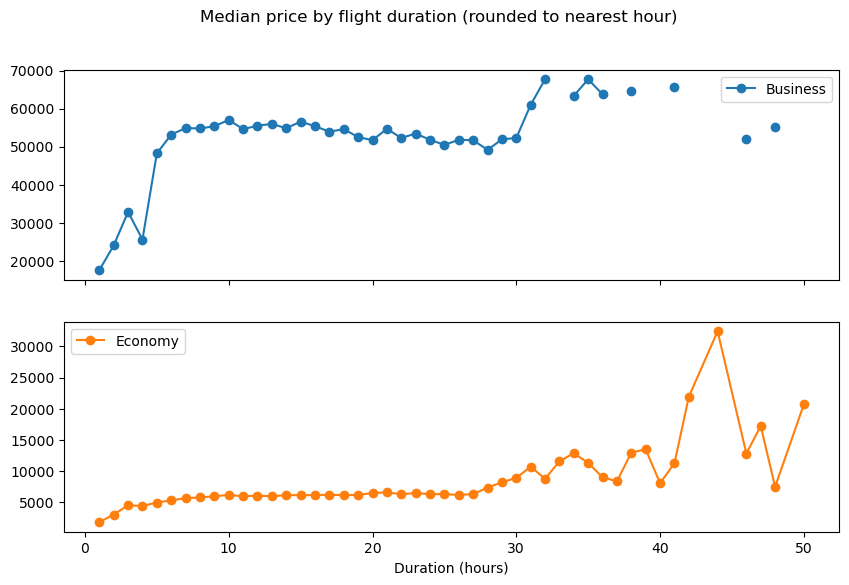

In [37]:
## Duration vs Price

duration_hours = df["duration"].round()

median_by_duration = df.groupby([duration_hours, "class"])["price"].median().unstack()

median_by_duration.plot(subplots=True, figsize=(10, 6), marker="o",
                        title="Median price by flight duration (rounded to nearest hour)")
plt.xlabel("Duration (hours)")
plt.show()

In [39]:
print("Tickets over 30 hours:", (df["duration"] > 30).sum())
print("Share of all tickets: ", round((df["duration"] > 30).mean() * 100, 2), "%")

Tickets over 30 hours: 2226
Share of all tickets:  0.74 %


**Finding 7:** Price rises quickly with duration for short flights (up to ~6 hours; mostly non-stop),
then levels off between ~6 and ~27 hours. Beyond 30 hours the chart becomes jumpy, but only 2,226 tickets (0.74%)
are that long, so each point rests on few tickets. These are real fares, not errors, so they were kept;
predictions for very long flights will be less reliable.

In very short:
Short flights get pricier as they get longer, medium-length flights all cost about the same because extra time is just layover, and very long flights are too rare to read clearly.

class           Business  Economy
departure_time                   
Early_Morning    53645.0   5778.0
Morning          53164.0   6067.0
Afternoon        52063.0   5656.0
Evening          53512.0   5507.0
Night            53209.0   5525.0
Late_Night       52586.0   4439.0

departure_time
Early_Morning    66790
Morning          71146
Afternoon        47794
Evening          65102
Night            48015
Late_Night        1306
Name: count, dtype: int64


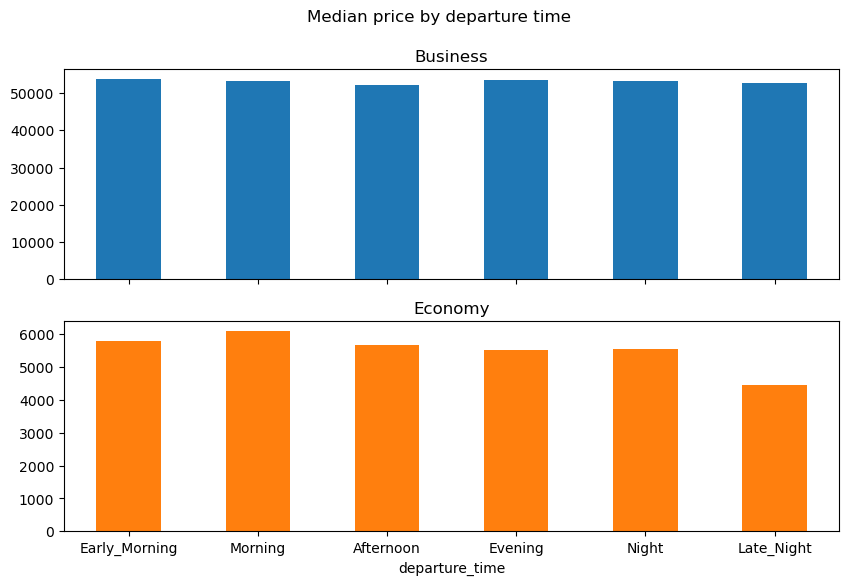

In [42]:
time_order = ["Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"]

median_by_dep = df.groupby(["departure_time", "class"])["price"].median().unstack().reindex(time_order)
print(median_by_dep)
print()
print(df["departure_time"].value_counts().reindex(time_order))

median_by_dep.plot(kind="bar", subplots=True, figsize=(10, 6), legend=False,
                   title="Median price by departure time")
plt.xticks(rotation=0)
plt.show()

class          Business  Economy
arrival_time                    
Early_Morning   45257.0   5029.0
Morning         52586.0   5660.0
Afternoon       50957.0   5437.0
Evening         54684.0   6170.0
Night           54115.0   5873.0
Late_Night      54608.0   4449.0

arrival_time
Early_Morning    15417
Morning          62735
Afternoon        38139
Evening          78323
Night            91538
Late_Night       14001
Name: count, dtype: int64


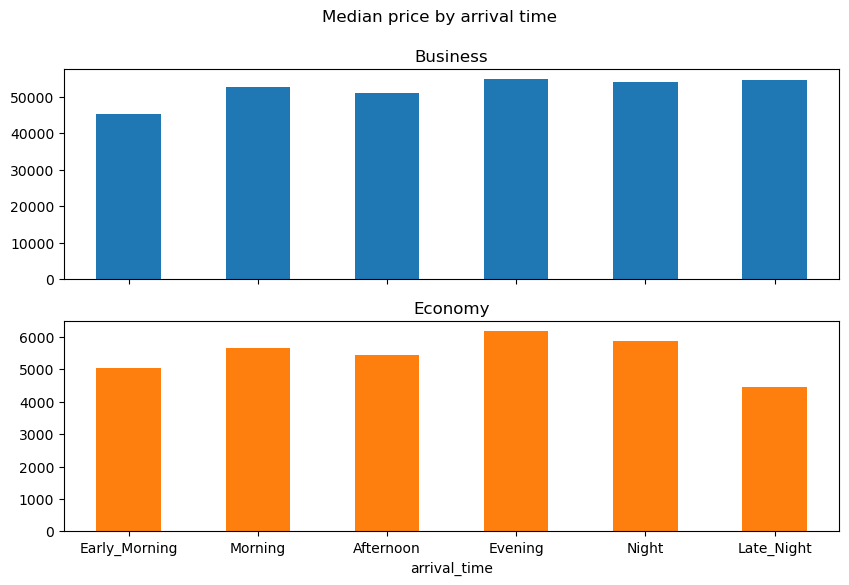

In [44]:
median_by_arr = df.groupby(["arrival_time", "class"])["price"].median().unstack().reindex(time_order)
print(median_by_arr)
print()
print(df["arrival_time"].value_counts().reindex(time_order))

median_by_arr.plot(kind="bar", subplots=True, figsize=(10, 6), legend=False,
                   title="Median price by arrival time")
plt.xticks(rotation=0)
plt.show()

In [46]:
economy = df[df["class"] == "Economy"]

route_prices = economy.pivot_table(index="source_city", columns="destination_city",
                                   values="price", aggfunc="median")
route_prices

destination_city,Bangalore,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
source_city,,,,,,
Bangalore,NaN,6161.0,4500.0,5808.0,6271.0,6191.0
Chennai,6161.0,NaN,5100.0,4714.0,5937.0,5037.0
Delhi,4500.0,4979.0,NaN,5761.0,5955.0,5284.0
Hyderabad,5441.0,4674.0,5823.0,NaN,5960.0,4660.0
Kolkata,6489.0,6489.0,6461.0,6488.0,NaN,6067.0
Mumbai,6319.0,4732.0,5445.0,4263.0,5949.0,NaN


**Finding 10:** Route affects Economy price moderately (~1.5× between cheapest and dearest routes).
Cheapest: Mumbai → Hyderabad (median ₹4,263) and Delhi ↔ Bangalore (₹4,500). Flights departing Kolkata are the most expensive
(₹6,067–₹6,489). Price does not follow distance: long Delhi → Bangalore is cheap while short Bangalore → Chennai costs ₹6,161,
possibly because of how many non-stop flights each route has. Cities have no order, so they will be treated as nominal.

In [49]:
os.makedirs("../Data", exist_ok=True)
df.to_csv("../Data/flights_clean.csv", index=False)
print("Saved:", df.shape)

Saved: (300153, 10)
